# Lab: Implementing Diffusion Models — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/03-keras-and-tensorflow/notebooks/lab-implementing-diffusion-models.ipynb) · [Course notes](../../../courses/03-keras-and-tensorflow/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Bundled TensorFlow datasets use 512 training / 256 test examples; fit inputs use at most 512 examples or eight dataset batches.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader
import tensorflow as tf
tf.random.set_seed(42)
for _dataset in [tf.keras.datasets.mnist,tf.keras.datasets.fashion_mnist,tf.keras.datasets.cifar10]:
    _original_load = _dataset.load_data
    def _small_load(*args,_load=_original_load,**kwargs):
        (x,y),(xt,yt) = _load(*args,**kwargs)
        return (x[:512],y[:512]),(xt[:256],yt[:256])
    _dataset.load_data = _small_load
_keras_fit = tf.keras.Model.fit
def _small_fit(self,*args,**kwargs):
    args = list(args)
    def _limit(value):
        if isinstance(value,(np.ndarray,pd.DataFrame,pd.Series)):return value[:512]
        if isinstance(value,(tuple,list)) and value and all(isinstance(x,np.ndarray) for x in value):return type(value)(x[:512] for x in value)
        if isinstance(value,tf.data.Dataset):return value.take(8)
        return value
    for i in range(min(2,len(args))):args[i]=_limit(args[i])
    for key in ['x','y','validation_data']:
        if key in kwargs:kwargs[key]=_limit(kwargs[key])
    kwargs['epochs']=min(2,kwargs.get('epochs',2))
    data=args[0] if args else kwargs.get('x')
    if hasattr(data,'class_indices'):
        kwargs['steps_per_epoch']=min(2,len(data))
        if hasattr(kwargs.get('validation_data'),'class_indices'):
            kwargs['validation_steps']=min(2,len(kwargs['validation_data']))
    return _keras_fit(self,*args,**kwargs)
tf.keras.Model.fit = _small_fit


Matplotlib is building the font cache; this may take a moment.


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Lab: Implementing Diffusion Models**


Estimated time needed: **45** minutes


In this lab, you will learn how to implement, train, and evaluate diffusion models using Keras. 


## Learning Objectives

By the end of this lab, you will: 
- Acquire practical understanding of diffusion model architectures, data processing, model training, and performance evaluation 
- Implement, train, and evaluate diffusion models using Keras 


----


### Prerequisites 

- Basic understanding of Python and Keras 


### Steps 

#### Step 1: Preprocess data 

Prepare the MNIST data set for training by normalizing the pixel values and reshaping the images to have a single color channel. Normalization helps in faster convergence during training, and reshaping is required because the input layer of your diffusion model expects a three-dimensional tensor. 

**1. Load and preprocess the MNIST data set:**

- Use Keras to load the MNIST data set. 
- Normalize the image pixel values to the range [0, 1]. 

**2. Reshape the Data:**
- Expand the dimensions of the images to match the input shape required by the model (28x28x1). 


In [2]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Reshape, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
noise_factor = 0.5
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

#### Step 2: Build the diffusion model 

Build a simple diffusion model with an encoder that compresses the input image into a latent representation and a decoder that reconstructs the image from this representation. The model is compiled with the Adam optimizer and binary cross-entropy loss. 

**1. Define the encoder:**
- Create an input layer with the shape (28, 28, 1). 
- Add two Conv2D layers with increasing filter sizes and ReLU activation. 

**2. Define the bottleneck:**
- Add a flattened layer followed by a dense layer with ReLU activation. 

**3. Define the decoder:**
- Add a Dense layer to expand the bottleneck representation.  
- Reshape the output to match the original image dimensions.  
- Add two Conv2DTranspose layers with decreasing filter sizes and ReLU activation.
  
**4. Compile the model:**
- Use the Adam optimizer and binary cross-entropy loss. 


In [4]:
input_layer = Input(shape=(28, 28, 1))
x = Conv2D(16, (3, 3), activation='relu', padding='same')(input_layer)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = Flatten()(x)
x = Dense(64, activation='relu')(x)
x = Dense(28 * 28 * 32, activation='relu')(x)
x = Reshape((28, 28, 32))(x)
x = Conv2DTranspose(32, (3, 3), activation='relu', padding='same')(x)
x = Conv2DTranspose(16, (3, 3), activation='relu', padding='same')(x)
output_layer = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)
diffusion_model = Model(input_layer, output_layer)
diffusion_model.compile(optimizer='adam', loss='mean_squared_error')
diffusion_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,605,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25088)          │     1,630,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 28, 28, 32)     │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,255,233 (12.42 MB)

 Trainable params: 3,255,233 (12.42 MB)

 Non-trainable params: 0 (0.00 B)

#### Step 3: Add noise to the data 

Add random noise to the data set to simulate the diffusion process: 
- Add Gaussian noise to the training and test data sets.  
- Clip the values to ensure they remain within the valid range [0, 1].  


In [5]:
train_dataset = tf.data.Dataset.from_tensor_slices((x_train_noisy, x_train))
train_dataset = train_dataset.cache().batch(64).prefetch(tf.data.AUTOTUNE)
val_dataset = tf.data.Dataset.from_tensor_slices((x_test_noisy, x_test))
val_dataset = val_dataset.cache().batch(64).prefetch(tf.data.AUTOTUNE)

#### Step 4: Train the diffusion model 

Train the diffusion model to denoise the MINIST images. Use the noisy images as input and the original images as the target, learning to reverse the noise addition process. 
- Use the ‘fit’ method to train the model on the noisy training data. 
- Set the number of epochs to 50 and the batch size to 128. 


In [6]:
early_stopping = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
diffusion_model.fit(train_dataset, epochs=2, shuffle=True, validation_data=val_dataset, callbacks=[early_stopping])

Epoch 1/2


1/8 ━━━━━━━━━━━━━━━━━━━━ 4s 705ms/step - loss: 0.2314

2/8 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 0.2312

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 0.2307

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 0.2296

5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - loss: 0.2278

... (10 outputs left out)

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 0.0864

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 0.0858

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 0.0852

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - loss: 0.0848 - val_loss: 0.0720


#### Step 5: Evaluate the diffusion model 

Evaluate the performance of the trained diffusion model by predicting the denoised images and visualizing the results. Comparing the original, noisy, and denoised images will help you understand how well the model has learned to remove noise from the images. 

**1. Reconstruct images:**
- Use the diffusion model to predict the denoised test images.  
- Compare the original, noisy, and denoised images. 

**2. Visualize the results:**
- Plot a few examples of original, noisy, and denoised images side by side. 


1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


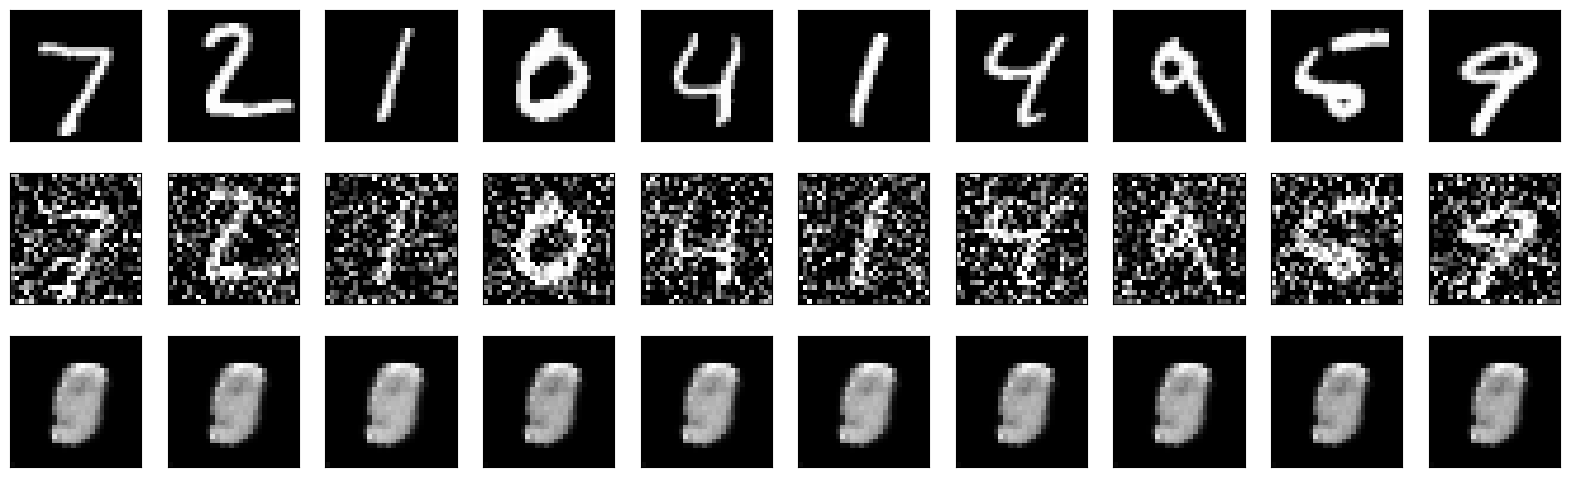

In [7]:
import matplotlib.pyplot as plt
denoised_images = diffusion_model.predict(x_test_noisy)
n = 10
plt.figure(figsize=(20, 6))
for i in range(n):
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised_images[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

#### Step 6: Fine-tune the diffusion model 

Fine-tune the diffusion model by unfreezing some layers and retraining the model to improve its performance. 


**1. Freeze the model layers:**
- Freeze all the layers of the encoder.

**2. Check the Status:** 
- Checking the trainable status of each layer.

**3. Unfreeze the model layers:** 
- Unfreeze the last few layers of the model to allow them to be retrained. 

**4. Compile and train the model:** 
- Recompile the model. 
- Train the model again for an additional 10 epochs. 


In [8]:
for layer in diffusion_model.layers:
    layer.trainable = False

In [9]:
for i, layer in enumerate(diffusion_model.layers):
    print(f'Layer {i}: {layer.name} — Trainable: {layer.trainable}')

Layer 0: input_layer — Trainable: False
Layer 1: conv2d — Trainable: False
Layer 2: conv2d_1 — Trainable: False
Layer 3: flatten — Trainable: False
Layer 4: dense — Trainable: False
Layer 5: dense_1 — Trainable: False
Layer 6: reshape — Trainable: False
Layer 7: conv2d_transpose — Trainable: False
Layer 8: conv2d_transpose_1 — Trainable: False
Layer 9: conv2d_2 — Trainable: False


In [10]:
for layer in diffusion_model.layers[-4:]:
    layer.trainable = True
diffusion_model.compile(optimizer='adam', loss='binary_crossentropy')
diffusion_model.fit(x_train_noisy, x_train, epochs=2, batch_size=64, shuffle=True, validation_data=(x_test_noisy, x_test))

Epoch 1/2


1/8 ━━━━━━━━━━━━━━━━━━━━ 2s 380ms/step - loss: 0.4864

2/8 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 0.4690 

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.4583

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.4495

5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.4401

... (10 outputs left out)

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.3027

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.3016

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.3006

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - loss: 0.2997 - val_loss: 0.2747


# Exercises

### Exercise 1: Modify the noise factor  

#### Objective: 
- Change the noise factor and see how it affects the model’s ability to denoise images.
#### Instructions:  
1. Change the noise factor to 0.3.  
2. Add noise to the training and test data sets with the new noise factor.  
3. Retrain the model with the new noisy data.


In [11]:
noise_factor = 0.3
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)
diffusion_model.fit(x_train_noisy, x_train, epochs=2, batch_size=128, shuffle=True, validation_data=(x_test_noisy, x_test))

Epoch 1/2


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 350ms/step - loss: 0.2850

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - loss: 0.2867

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - loss: 0.2868

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - loss: 0.2863

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 265ms/step - loss: 0.2860 - val_loss: 0.2764


... (2 outputs left out)

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - loss: 0.2830

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - loss: 0.2837

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - loss: 0.2837

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 244ms/step - loss: 0.2837 - val_loss: 0.2763


<details>
    <summary>Click here for Solution</summary>

```python
# Modify the noise factor to 0.3  
noise_factor = 0.3  
   
# Add noise to the data with the new noise factor  
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)  
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)  
  
# Clip the values to be within the range [0, 1]  
x_train_noisy = np.clip(x_train_noisy, 0., 1.)  
x_test_noisy = np.clip(x_test_noisy, 0., 1.)  
   
# Retrain the model  
diffusion_model.fit(x_train_noisy, x_train,    
                    epochs=50,    
                    batch_size=128,    
                    shuffle=True,    
                    validation_data=(x_test_noisy, x_test))  
```

</details>


### Exercise 2 - Add more layers to the model  

#### Objective: 
- Experiment with adding more layers to the model to see how it affects performance.

#### Instructions:
1. Add an additional Conv2D layer with 128 filters in the encoder.  
2. Add an additional Conv2DTranspose layer with 128 filters in the decoder.  
3. Rebuild, compile, and train the model.


In [12]:
input_layer = Input(shape=(28, 28, 1))
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_layer)
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dense(28 * 28 * 64, activation='relu')(x)
x = Reshape((28, 28, 64))(x)
x = Conv2DTranspose(128, (3, 3), activation='relu', padding='same')(x)
x = Conv2DTranspose(64, (3, 3), activation='relu', padding='same')(x)
x = Conv2DTranspose(32, (3, 3), activation='relu', padding='same')(x)
output_layer = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)
diffusion_model = Model(input_layer, output_layer)
diffusion_model.compile(optimizer='adam', loss='binary_crossentropy')
diffusion_model.summary()
diffusion_model.fit(x_train_noisy, x_train, epochs=2, batch_size=128, shuffle=True, validation_data=(x_test_noisy, x_test))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50176)          │     6,472,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 128)    │        73,856 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,576,961 (74.68 MB)

 Trainable params: 19,576,961 (74.68 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2


... (7 outputs left out)

2/4 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step - loss: 0.3164

3/4 ━━━━━━━━━━━━━━━━━━━━ 2s 3s/step - loss: 0.3143

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.3108

4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - loss: 0.3086 - val_loss: 0.2723


<details>
    <summary>Click here for Solution</summary>

```python
# Define the modified diffusion model architecture with additional layers
input_layer = Input(shape=(28, 28, 1))

x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_layer)
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = Conv2D(128, (3, 3), activation='relu', padding='same')(x) # Additional layer
x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dense(28*28*64, activation='relu')(x)
x = Reshape((28, 28, 64))(x)
x = Conv2DTranspose(128, (3, 3), activation='relu', padding='same')(x) # Additional layer
x = Conv2DTranspose(64, (3, 3), activation='relu', padding='same')(x)
x = Conv2DTranspose(32, (3, 3), activation='relu', padding='same')(x)
output_layer = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

diffusion_model = Model(input_layer, output_layer)

# Compile the model  
diffusion_model.compile(optimizer='adam', loss='binary_crossentropy')
   

# Summary of the model  
diffusion_model.summary()

# Train the model  
diffusion_model.fit(x_train_noisy, x_train,
                    epochs=50,
                    batch_size=128,
                    shuffle=True,
                    validation_data=(x_test_noisy, x_test))
```

</details>


### Exercise 3: Visualize the effect of noise  

#### Objective: 
- Compare the impact of different noise levels on the denoising performance of the model.

#### Instructions:  
1. Add noise with different factors (e.g., 0.1, 0.5, 0.7) to the test data.  
2. Use the model to predict the denoised images for each noise level.  
3. Visualize the original, noisy, and denoised images side by side for each noise level.


1/8 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step

2/8 ━━━━━━━━━━━━━━━━━━━━ 1s 234ms/step

3/8 ━━━━━━━━━━━━━━━━━━━━ 1s 235ms/step

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step

5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step

... (17 outputs left out)

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 233ms/step


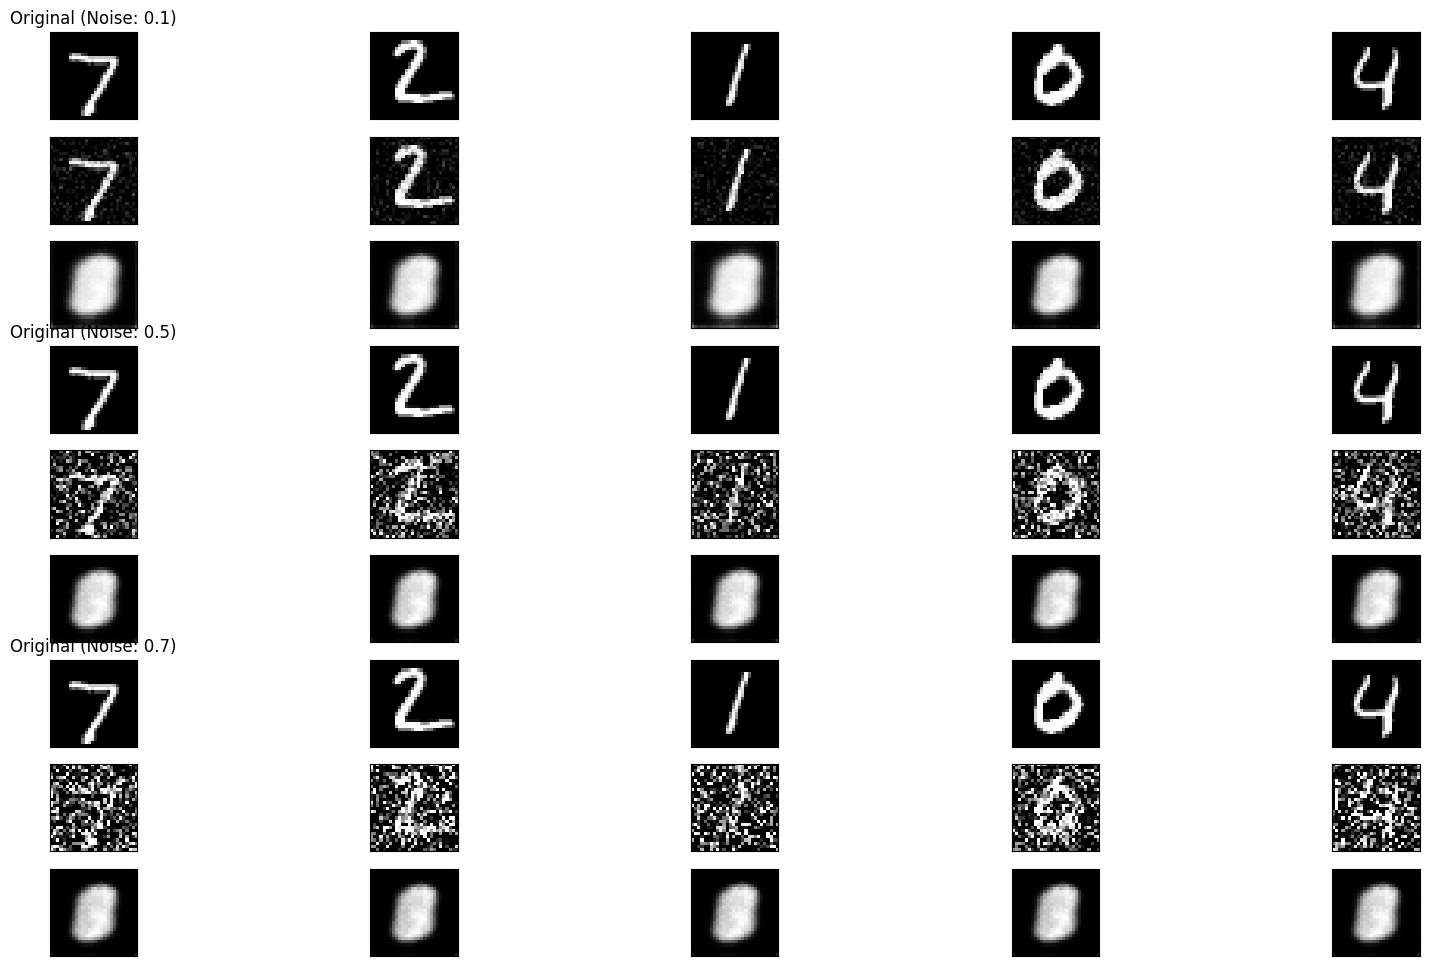

In [13]:
import matplotlib.pyplot as plt

def add_noise_and_predict(noise_factor):
    x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
    x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)
    denoised_images = diffusion_model.predict(x_test_noisy)
    return (x_test_noisy, denoised_images)
noise_levels = [0.1, 0.5, 0.7]
n = 5
plt.figure(figsize=(20, 12))
for idx, noise_factor in enumerate(noise_levels):
    x_test_noisy, denoised_images = add_noise_and_predict(noise_factor)
    for i in range(n):
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + idx * 3 * n)
        plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
        if i == 0:
            ax.set_title(f'Original (Noise: {noise_factor})')
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + n + idx * 3 * n)
        plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + 2 * n + idx * 3 * n)
        plt.imshow(denoised_images[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
import matplotlib.pyplot as plt
   

# Function to add noise and predict denoised images
def add_noise_and_predict(noise_factor):
    x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
    x_test_noisy = np.clip(x_test_noisy, 0., 1.)
    denoised_images = diffusion_model.predict(x_test_noisy)
    return x_test_noisy, denoised_images

# Noise levels to test
noise_levels = [0.1, 0.5, 0.7]
   
# Visualize the results
n = 5  # Number of digits to display
plt.figure(figsize=(20, 12))
for idx, noise_factor in enumerate(noise_levels):
    x_test_noisy, denoised_images = add_noise_and_predict(noise_factor)
    
    for i in range(n):
        # Display original
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + idx * 3 * n)
        plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)  

        if i == 0:
            ax.set_title(f'Original (Noise: {noise_factor})')
          
        # Display noisy
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + n + idx * 3 * n)
        plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)  


        # Display denoised
        ax = plt.subplot(3 * len(noise_levels), n, i + 1 + 2 * n + idx * 3 * n)
        plt.imshow(denoised_images[i].reshape(28, 28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)  
plt.show()
```

</details>


### Summary  

By completing these exercises, students will:  
1. Understand the impact of different noise factors on the model’s denoising capabilities.
2. Learn how adding more layers to the model affects its performance.
3. Visualize how different levels of noise affect the denoising results of the model. 


### Conclusion 

Congratulations! You have gained practical experience in implementing diffusion models using Keras. You learned how to preprocess data, construct a basic diffusion model architecture, add noise to the data set, train the model, and evaluate its performance. Additionally, you explored fine-tuning techniques to enhance the model’s performance. 


Copyright © IBM Corporation. All rights reserved.
